# Ứng dụng: phân vùng ảnh bằng K-means

*Bài 8, mục 8.1.2.* Mỗi điểm ảnh (pixel) là một điểm dữ liệu trong không gian màu RGB 3 chiều. K-means nhóm các pixel có màu gần nhau; thay mỗi pixel bằng màu của tâm cụm ta được ảnh chỉ còn $K$ màu, các vùng màu tương tự được gộp lại.

Ảnh mẫu `china.jpg` có sẵn trong scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image

image = load_sample_image('china.jpg')
print('Kích thước ảnh:', image.shape)
pixels = image.reshape(-1, 3).astype(float) / 255     # mỗi hàng là một pixel (R, G, B) trong [0, 1]
print('Số điểm dữ liệu:', pixels.shape)

Kích thước ảnh: (427, 640, 3)
Số điểm dữ liệu: (273280, 3)


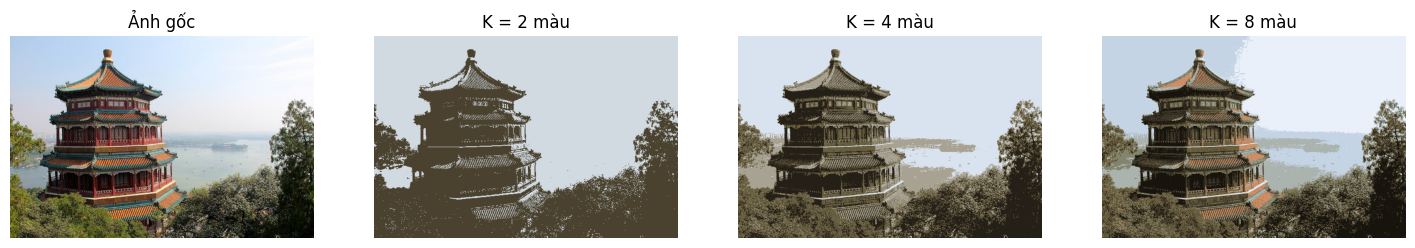

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].imshow(image); axes[0].set_title('Ảnh gốc'); axes[0].axis('off')
for ax, k in zip(axes[1:], [2, 4, 8]):
    model = KMeans(n_clusters=k, n_init=3, random_state=0).fit(pixels[::20])   # học tâm trên 5% pixel cho nhanh
    labels = model.predict(pixels)                                             # gán mọi pixel vào cụm
    segmented = model.cluster_centers_[labels].reshape(image.shape)
    ax.imshow(segmented); ax.set_title('K = %d màu' % k); ax.axis('off')
plt.show()

Ảnh gốc có hàng chục nghìn màu khác nhau; với $K = 8$ ảnh vẫn giữ được hầu hết cấu trúc. Kỹ thuật này còn gọi là **lượng tử hóa màu** (color quantization), dùng để nén ảnh: chỉ cần lưu $K$ màu và chỉ số cụm của mỗi pixel.

In [3]:
print('Số màu khác nhau trong ảnh gốc:', len(np.unique(image.reshape(-1, 3), axis=0)))

Số màu khác nhau trong ảnh gốc: 96615
